# Predicting AI system performance with audited belief revision
### A reproducible PAIEC BLE 1.5-A walkthrough

<a id="overview"></a>

## 00 · Executive overview

A model's average benchmark score cannot answer a practical question: **will this
particular system, in this harness, solve this particular item?** PAIEC asks us to
forecast that probability without running the target system on the item.

| **0.1590607804** | **9 groups** | **489 distinct pairs** | **6 budgets** |
|:---|:---|:---|:---|
| Official formative Brier ALC | Equal-weight subject–benchmark groups | 2,934 nominal pair-budget slots | 0 · 1 · 3 · 7 · 15 · 31 |

**Two results, two kinds of evidence.** On a frozen, public two-budget comparison,
research R1 reduced Brier from 0.203883 to 0.153728. The hosted score above is from
the later bounded BLE 1.5-A implementation (#1032237), on a different sample with
a six-budget metric. The public experiment supports a paired improvement on that
panel. The hosted evaluation establishes that scored A finished. Neither
isolates retrieval's causal benefit, and the score does not expose counted runtime.

**Read this notebook with three labels in mind.** *Synthetic* means invented
teaching data. *Recomputed aggregate* means arithmetic on released summary cells.
*Official* means reported by the hosted scorer. The offline default uses no
credentials, no model downloads and no network.

**Contents**  
[01 Competition](#competition) · [02 Baselines](#baselines) · [03 Belief revision](#beliefs) ·
[04 Scored implementation](#production) · [05 Retrieval](#retrieval) · [06 Public evidence](#public) ·
[07 Hosted dashboard](#hosted) · [08 Decisions](#decisions) · [09 Reliability](#reliability) ·
[10 Reproduce](#reproduce) · [11 Conclusions](#conclusions)

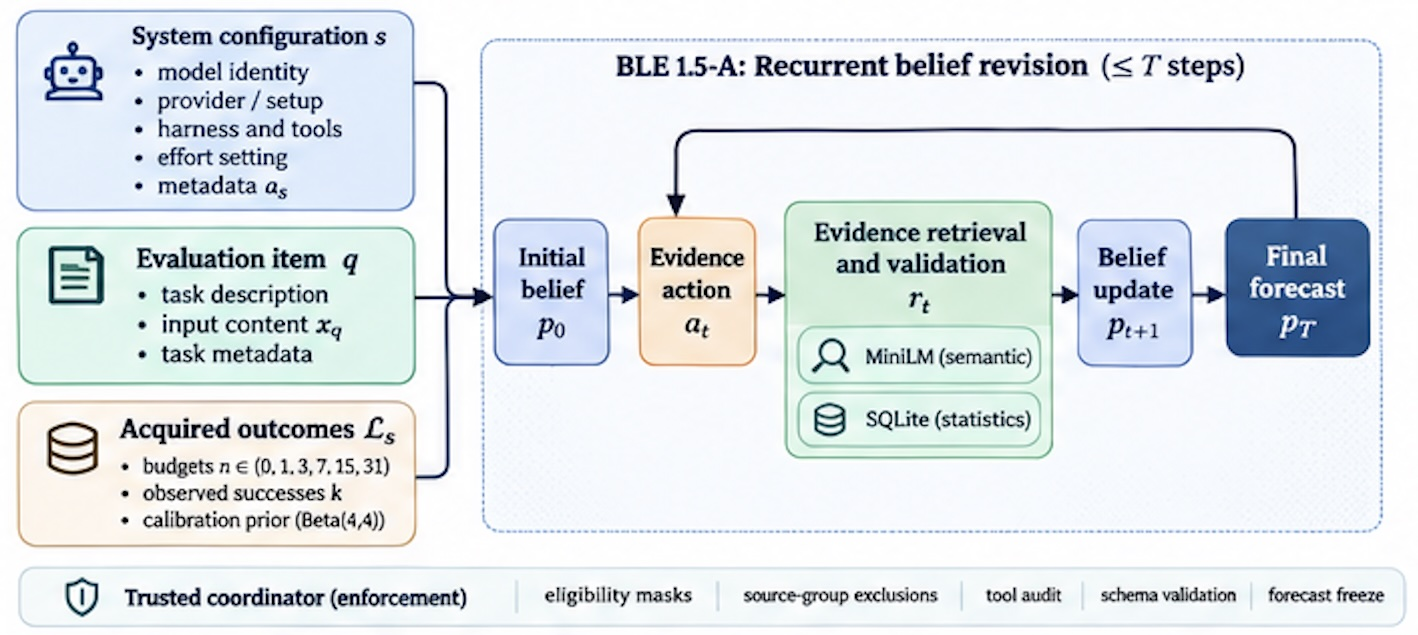

In [1]:
from decimal import Decimal
import inspect
import json
import math
from pathlib import Path
import sys

from IPython.display import Image, display
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "hosted-ble15a").is_dir() else Path.cwd().parent
assert (ROOT / "hosted-ble15a").is_dir(), "Start from the repository root or notebooks/"
sys.path.insert(0, str(ROOT))
from examples.offline_walkthrough import RUNTIME, ROWS, TARGET, LABELS, run_demo, typed_action

NAVY, BLUE, TEAL = "#172843", "#386D9C", "#147F79"
AMBER, RED, LAVENDER, GRID = "#9A6016", "#A54C59", "#6C6194", "#E3E9EF"
plt.rcParams.update({
    "font.size": 10.5, "font.family": "DejaVu Sans", "text.color": NAVY,
    "axes.labelcolor": NAVY, "axes.edgecolor": GRID, "axes.titlecolor": NAVY,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.spines.top": False,
    "axes.spines.right": False, "xtick.color": NAVY, "ytick.color": NAVY,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "figure.dpi": 125, "axes.axisbelow": True,
})

def read_json(relative):
    return json.loads((ROOT / relative).read_text())

def show_figure(name):
    display(Image(data=(ROOT / "figures" / name).read_bytes(), width=800))

show_figure("approved_architecture.png")

*Approved manuscript Figure 1.* The model proposes the belief and the action.
The coordinator determines whether and how to retrieve. We will follow those
responsibilities separately before putting them together.

<a id="competition"></a>

## 01 · Understand the competition

A **subject** is a configured AI system, including the model, harness and inference
settings. An **item** is the task and visible metadata. The target $y$ is a binary
response outcome. Your predictor receives the subject and item, plus a budgeted
set of revealed outcomes for the same group. Its contract is
**predict([subject, item], labeled) → one finite probability**.

Allowed evidence comes from the organizer's benchmark inventory and legitimately
revealed labels, subject to source and target exclusions. The held-out target
outcome, its protected variants, and scoring-time search or grounding are outside
this evidence boundary. A model that accidentally retrieves its answer key may
score well for the wrong reason. An honest probability should also be calibrated:
among comparable predictions of 0.8, roughly 80% should occur.

For one event, Brier loss is $(p-y)^2$. First average losses inside each
subject–benchmark group and budget. Then take the fixed six-budget weighted sum
**0.1, 0.2, 0.2, 0.2, 0.2, 0.1** and give each group equal weight. A large group
contributes the same weight to ALC as a small group.
[Official PAIEC rules and interface](https://aims.stanford.edu/competition)

In [2]:
BUDGETS = (0, 1, 3, 7, 15, 31)
WEIGHTS = tuple(map(Decimal, ("0.1", "0.2", "0.2", "0.2", "0.2", "0.1")))

def brier(probabilities, outcomes):
    if not probabilities or len(probabilities) != len(outcomes):
        raise ValueError("Provide matching nonempty forecasts and outcomes")
    if any(not 0 <= p <= 1 for p in probabilities) or any(y not in (0, 1) for y in outcomes):
        raise ValueError("Expected probabilities in [0,1] and binary outcomes")
    return sum((p - y) ** 2 for p, y in zip(probabilities, outcomes)) / len(outcomes)

def alc(values):
    if set(values) != set(BUDGETS):
        raise ValueError("ALC requires all six acquisition budgets")
    numbers = [Decimal(str(values[b])) for b in BUDGETS]
    if any(not v.is_finite() or not 0 <= v <= 1 for v in numbers):
        raise ValueError("Expected finite Brier losses in [0,1]")
    return sum(w * v for w, v in zip(WEIGHTS, numbers))

toy_group_a = dict(zip(BUDGETS, (.25, .21, .18, .17, .15, .14)))
toy_group_b = dict(zip(BUDGETS, (.25, .25, .23, .22, .21, .19)))
print(f"Synthetic two-event Brier: {brier([.8, .3], [1, 0]):.3f}")
print(f"Synthetic group ALCs: {alc(toy_group_a):.3f} and {alc(toy_group_b):.3f}")
print(f"Equal-group synthetic ALC: {(alc(toy_group_a) + alc(toy_group_b)) / 2:.4f}")
assert math.isclose(brier([.8, .3], [1, 0]), .065)
assert alc(dict.fromkeys(BUDGETS, .25)) == Decimal(".25")

Synthetic two-event Brier: 0.065
Synthetic group ALCs: 0.181 and 0.226
Equal-group synthetic ALC: 0.2035


The two event losses are 0.04 and 0.09. The constant 0.5 probability gives
0.25 for either binary outcome. It is a useful reference line. A paired model
comparison needs the same actual outcomes, sample and aggregation.

<a id="baselines"></a>

## 02 · The simplest useful baseline

Start with a Beta(4,4) prior for the subject's success rate. If $k$ of $n$
revealed responses were correct, its posterior mean is $(4+k)/(8+n)$.
This shrinks sparse rates toward 0.5. The rule treats distinct unseen items with
the same revealed history identically.

The **direct Luna A0** research comparator can see the item and metadata, so
it can differentiate questions. Its one-shot prompt omits the recurrent audited
retrieval path. In the public confirmation, direct A0 scored **0.203883** and
Beta(4,4) **0.221448**, both lower-is-better Brier scores. Those numbers belong
to the controlled public panel. Neither was run as a matched hosted comparator
for #1032237.

In [3]:
from r1api.predictor_common import beta44, matching_labels
toy_label = matching_labels(TARGET, LABELS)
assert len(toy_label) == 1
print(f"Exact Beta rule, zero labels: {beta44([]):.3f}")
print(f"Exact Beta rule, one success: {beta44(toy_label):.3f}")

Exact Beta rule, zero labels: 0.500
Exact Beta rule, one success: 0.556


A stronger prior is useful when evidence is sparse. It cannot tell whether the
next item calls for a capability this subject lacks. That is the role of item
conditioning and, where useful, comparable measurements.

<a id="beliefs"></a>

## 03 · The BLE research idea

AIMS Foundations supplied the original Bayesian Linguistic Evaluator. We
instrument its observable state $S_t=(x,E_t,b_t,h_t)$. Here $x$ is the fixed task
and labels, $E_t$ the admitted evidence, $b_t$ an explicit belief including a
probability, and $h_t$ the action history. This is a measurement interface around
an LLM. It does not train a recurrent neural architecture or guarantee exact
Bayesian updates.

At step $t$ the model emits a probability based on evidence **already seen** and
chooses one action. The controller validates it and returns admissible evidence.
The next response can revise its belief. Retrieval itself never edits a
probability. When a valid submit action arrives, its explicit final probability
takes precedence over its accompanying belief field. An earlier readout after an
interruption is recorded separately.
[Organizer BLE implementation](https://github.com/aims-foundations/paiec_baseline)

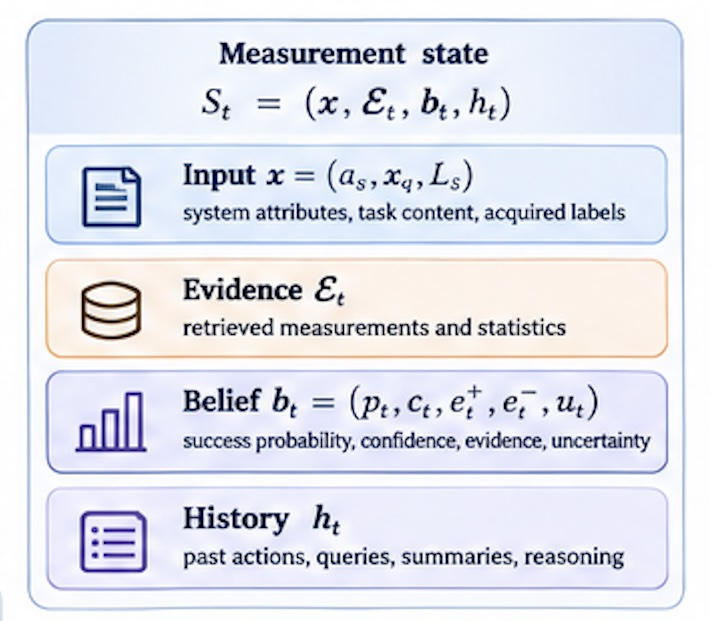

In [4]:
show_figure("approved_measurement_state.png")

*Approved manuscript Figure 7.* For the worked example below, a toy solver starts
at 0.55, asks for a filtered score packet and submits 0.68 after seeing it.
**These two probabilities are invented.** Archived outcomes and raw research
trajectories are outside this public release. In Section 05 the actual scored
controller will execute these mock actions against a toy database.

<a id="production"></a>

## 04 · Read the actual scored 1.5-A source

Three labels in this repository prevent a common mix-up. **research-r1** is the
historical public study. **hosted-ble15a** is the selected scored Standard/Medium
runtime. **experimental-a2-fast** is a separate submission that failed.
The selected runtime is imported from the hash-verified public-safe source.
Below, we inspect the active path rather than using a model of its behavior
written from scratch.

| Purpose | Input | Operation | Output | Why it matters |
|---|---|---|---|---|
| Forecast interface | Subject, item, acquired records | Match full subject and benchmark; cap at 31; render compact examples | One question and permitted label prefix | Stops unrelated labels from conditioning a target |
| Request construction | Instructions, history, typed schema | Luna Medium, default tier, strict JSON, empty native tools list | One action response | Python owns dispatch and its evidence boundary |
| Continuation | Prior response items and new evidence | Replay opaque encrypted items intact | Next conditioned request | Preserves history without releasing private reasoning |
| Admissibility | Corpus and target/acquisition fingerprints | Verify frozen corpus/mask, apply dynamic item and source exclusions | Permitted candidate view | Blocks leakage into both item retrieval and score aggregates |
| Semantic retrieval | Query and frozen vectors | Local MiniLM, normalized dot product, candidate filters | Ranked candidate packets | Similar wording only proposes a potentially relevant analogue |
| SQL evidence | Group and subject query | Recompute affected counts over permitted rows | Successes, trials, coverage | Published all-item means can leak excluded rows |
| Final validation | Typed action with belief and probability | Validate arguments and finite probability | Native submit or explicit prior-belief readout | Returned number and completed reasoning are different |
| Runtime bounds | Deadline, request and transport state | Bound calls; allow one schema repair; preserve validated belief | Stop reason or validated finalization | Avoids wasting remaining wall time or silently accepting bad replies |
| Financial and transport guard | Request envelope and shared scope | Verify CA, reserve budget, guard retries, retain uncertain spend | Admitted request or fail-closed result | A timeout can still have consumed provider resources |

In [5]:
import model as scored_entry
from r1api.predictor import forecast, TOOLS
from r1api.protocol import SyntaxFailure, decode
from r1api.responses import ResponsesClient

policy = json.loads((RUNTIME / "rescue_policy.json").read_text())
cfg = json.loads((RUNTIME / "submission_config.json").read_text())
assert Path(inspect.getsourcefile(scored_entry.predict)).resolve() == RUNTIME / "production.py"
assert cfg["api_keys"] == {} and cfg["enable_paid_inference"] is False
lines = inspect.getsource(ResponsesClient.call).splitlines()
start = next(i for i, line in enumerate(lines) if "body = " in line)
print("\n".join(lines[start:start + 6]))
print("Local actions:", ", ".join(t["function"]["name"] for t in TOOLS))
display(pd.Series({k: policy[k] for k in [
    "maximum_valid_actions", "inference_deadline_seconds", "maximum_HTTP_call_seconds",
    "third_call_minimum_remaining_seconds", "maximum_Responses_requests_per_forecast"
]}, name="Frozen value").to_frame())

        body = {'model': MODEL, 'instructions': instructions, 'input': copy.deepcopy(history),
                'reasoning': {'mode': 'standard', 'effort': self.effort}, 'store': False,
                'include': ['reasoning.encrypted_content'], 'tools': [],
                'text': {'format': {'type': 'json_schema', 'name': 'r1_typed_action',
                                    'strict': True, 'schema': schema}},
                'max_output_tokens': self.output_cap, 'service_tier': self.requested_tier}
Local actions: submit, semantic_search_items, search_benchmarks, get_benchmark, find_model, get_scores, search_items, get_item, get_trace


,Frozen value
maximum_valid_actions,3
inference_deadline_seconds,31
maximum_HTTP_call_seconds,20
third_call_minimum_remaining_seconds,12
maximum_Responses_requests_per_forecast,4


The original model-visible prefix describes up to five actions. The scored
Completion controller admits at most **three valid actions**, four requests
including one repair, and uses a 31-second inference window after initialization.
A single request is capped at 20 seconds. The third call needs at least 12 seconds
of remaining time. The request body has **tools: []** because the JSON schema
describes a Python-dispatched action. There are no native function calls in this
scoring path. The bound is an engineering control, not a timing guarantee.

In [6]:
action = typed_action("submit", .68)
name, args = decode(action, TOOLS)
display(pd.DataFrame([{"provenance": "invented action", "tool": name,
                       "belief": args["updated_belief"]["p"], "submitted p": args["probability"]}]))
bad_action = typed_action("submit", 1.01)
try:
    decode(bad_action, TOOLS)
except SyntaxFailure:
    print("Synthetic out-of-range response rejected by the scored validator.")
else:
    raise AssertionError("The production schema should reject this probability")

,provenance,tool,belief,submitted p
0,invented action,submit,0.68,0.68


Synthetic out-of-range response rejected by the scored validator.


<a id="retrieval"></a>

## 05 · Audited retrieval in a four-row toy database

There are two questions before a record should move a belief. **May we show it?**
uses eligibility, target and source-group exclusions. **Does it actually transfer?**
depends on the model, harness, effort, task and sample size. An admissible record
can still be a weak analogue.

The production encoder embeds the query with pinned local MiniLM and compares
normalized vectors. The tiny vectors below are fabricated to expose the
similarity calculation. They are not MiniLM output. The controller example then
uses the **actual SQLite filtering and recomputation path** on invented records.
The target-copy outcome and its source sibling are deliberately present only in
the toy database so we can assert that neither reaches evidence.

In [7]:
names = ["relevant", "weak", "target-copy", "source-sibling"]
toy_vectors = np.array([[.94, .34], [.25, .97], [1., 0.], [.98, .20]])
toy_vectors /= np.linalg.norm(toy_vectors, axis=1, keepdims=True)
cosine = toy_vectors @ np.array([1., 0.])
demo = run_demo()
display(pd.DataFrame({
    "Invented item": names,
    "Toy cosine": np.round(cosine, 3),
    "Historical count": [f"{k}/{n}" for _, _, _, _, _, k, n in ROWS],
    "Disposition": ["admit · related", "admit · weak", "block · exact target", "block · same source"],
}))
assert demo["eligible"] == ["relevant", "weak"]
assert (demo["evidence"]["successes"], demo["evidence"]["trials"]) == (9, 20)
print(f"Actual filtered SQL count on invented records: {demo['evidence']['successes']}/{demo['evidence']['trials']}")

,Invented item,Toy cosine,Historical count,Disposition
0,relevant,0.94,7/10,admit · related
1,weak,0.25,2/10,admit · weak
2,target-copy,1.00,10/10,block · exact target
3,source-sibling,0.98,10/10,block · same source


Actual filtered SQL count on invented records: 9/20


A similarity-only rule would rank the blocked duplicate first. The exact filtered
aggregate is **9/20** rather than the unfiltered toy **29/40**. It describes past
trial outcomes; it does not mechanically become the target probability.

The next output is driven by the scored coordinator's event markers. Only the
transport and data are substituted. The mock endpoint asserts the actual request
model, tier, empty native tool list, encryption inclusion, and replay of the
opaque continuation item. It never opens a socket. The aggregate spending ledger
is deliberately outside this synthetic harness; its frozen implementation
remains in the release.

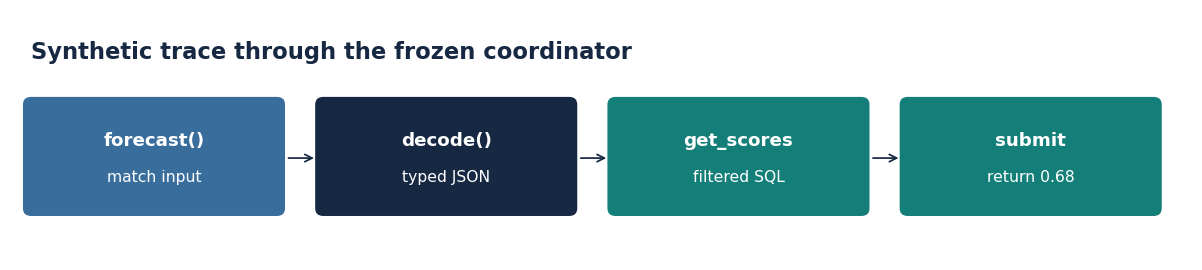

,probability,readout
Final submit,0.68,submitted
Interrupted after valid belief,0.55,intermediate_return
Interrupted before valid belief,0.555556,fallback


In [8]:
trace = demo["runs"]["Final submit"]
steps = [("forecast()", "match input", BLUE), ("decode()", "typed JSON", NAVY),
         (trace["actions"][0], "filtered SQL", TEAL),
         (trace["actions"][1], f"return {trace['probability']:.2f}", TEAL)]
assert trace["actions"] == ["get_scores", "submit"] and trace["beliefs"] == [.55, .68]
fig, ax = plt.subplots(figsize=(9.5, 2.05), layout="constrained")
ax.set(xlim=(0, 10.15), ylim=(0, 2.25))
ax.axis("off")
for i, (top, sub, color) in enumerate(steps):
    x = .16 + i * 2.52
    ax.add_patch(FancyBboxPatch((x, .45), 2.12, .95, boxstyle="round,pad=.07",
                                facecolor=color, edgecolor="none"))
    ax.text(x + 1.06, 1.03, top, ha="center", color="white", weight="bold")
    ax.text(x + 1.06, .70, sub, ha="center", color="white", fontsize=9)
    if i < len(steps) - 1:
        ax.annotate("", (x + 2.47, .91), (x + 2.19, .91),
                    arrowprops={"arrowstyle": "->", "color": NAVY})
ax.text(.16, 1.82, "Synthetic trace through the frozen coordinator", weight="bold", fontsize=13)
plt.show()
display(pd.DataFrame(demo["runs"]).T[["probability", "readout"]])

The mock finalizes at 0.68. Interrupting the second call returns the validated
0.55 as an intermediate readout. Interrupting before any belief uses Beta(4,4)
and the one legitimate revealed label. These are three different control paths,
even though the external interface returns one finite float in each case.

<a id="public"></a>

## 06 · What the controlled public experiment establishes

**Design.** The R1 confirmation froze predictions before unsealing outcomes.
It used 32 new questions from four previously encountered families, budgets
0 and 7, and separated source groups from development. That gives 64 matched
question-budget units, with related budgets and repeated outcomes kept together
for uncertainty calculations. It is a fresh-question check within known families.

**Recompute what is released.** The aggregate cells contain loss sums and trial
counts for direct, initial and final forecasts. Divide each cell's loss sum by
its trial count, then average cells according to the archived scorer. Beta(4,4)
and the clustered intervals are recorded results from the manuscript and
analysis reference. Raw accepted probabilities, outcomes and bootstrap units
are not redistributed.

In [9]:
from scripts.verify_results import aggregate

research = ROOT / "experiments/ble_audited_retrieval_002"
cell_data = json.loads((research / "confirmation_aggregate_cells.json").read_text())
reference = json.loads((research / "confirmation_reference.json").read_text())
computed = aggregate(research / "confirmation_aggregate_cells.json")
recorded = read_json("results/public_r1_recorded.json")
assert reference["paired_questions"] == 32 and reference["paired_units"] == 64
assert reference["source_groups_unique"] == 32
table = pd.DataFrame([
    {"Method": label, **computed[key], "Evidence": "Recomputed loss cells"}
    for key, label in [("A0", "Direct A0"), ("R1_initial", "Initial R1"), ("R1", "Final R1")]
] + [{"Method": "Beta(4,4)", **recorded["beta44"], "Evidence": "Recorded manuscript"}]).set_index("Method")
assert list(table.brier.round(6)) == [.203883, .172116, .153728, .221448]
assert list(table.nll.round(6)) == [.581099, .511191, .471989, .634511]
display(table.round(6))

,brier,nll,Evidence
Method,,,
Direct A0,0.203883,0.581099,Recomputed loss cells
Initial R1,0.172116,0.511191,Recomputed loss cells
Final R1,0.153728,0.471989,Recomputed loss cells
"Beta(4,4)",0.221448,0.634511,Recorded manuscript


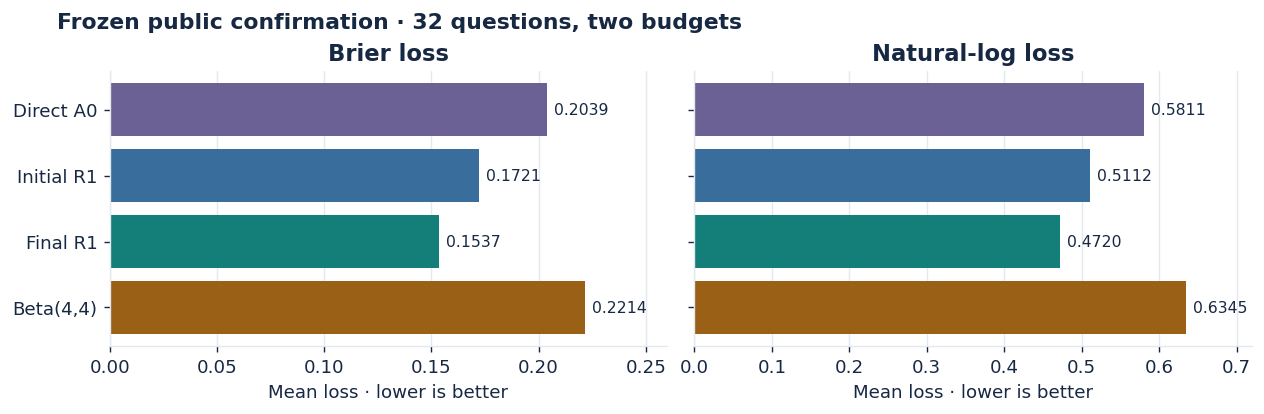

In [10]:
colors = [LAVENDER, BLUE, TEAL, AMBER]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout="constrained")
for ax, key, title, limit in [
    (axes[0], "brier", "Brier loss", .26), (axes[1], "nll", "Natural-log loss", .72)
]:
    values = table[key]
    bars = ax.barh(table.index, values, color=colors)
    ax.invert_yaxis()
    ax.bar_label(bars, fmt="%.4f", padding=4, color=NAVY, fontsize=9)
    ax.set(title=title, xlim=(0, limit), xlabel="Mean loss · lower is better")
    ax.grid(axis="x", color=GRID)
axes[1].tick_params(axis="y", labelleft=False)
fig.suptitle("Frozen public confirmation · 32 questions, two budgets", x=.04, ha="left", weight="bold")
plt.show()

Both proper scores improve from direct to final R1. The initial belief already
outperforms direct A0 before the recurrent evidence loop. Subtracting the paired
point estimates separates the **initial prompt/context gap** from the
**later revision gap**. Neither isolates a causal effect of retrieval.

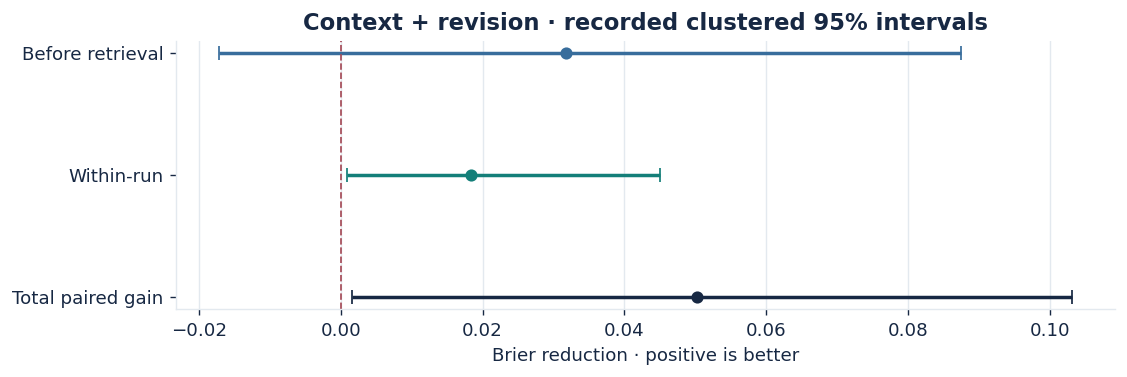

0.031767 + 0.018388 = 0.050155


In [11]:
direct, initial, final = (computed[k]["brier"] for k in ("A0", "R1_initial", "R1"))
gains = np.array([direct - initial, initial - final, direct - final])
recorded_gains = [reference[k] for k in (
    "prompting_improvement", "within_run_improvement", "paired_improvement"
)]
assert np.allclose(gains, [r["gain"] for r in recorded_gains], rtol=0, atol=1e-12)
limits = np.array([r["family_source_cluster_95"] for r in recorded_gains])
fig, ax = plt.subplots(figsize=(8.9, 2.9), layout="constrained")
for i, color in enumerate([BLUE, TEAL, NAVY]):
    ax.errorbar(gains[i], i, xerr=[[gains[i]-limits[i, 0]], [limits[i, 1]-gains[i]]],
                fmt="o", capsize=4, linewidth=2, color=color)
ax.axvline(0, color=RED, linestyle="--", linewidth=1)
ax.set(yticks=range(3), yticklabels=["Before retrieval", "Within-run", "Total paired gain"],
       xlabel="Brier reduction · positive is better",
       title="Context + revision · recorded clustered 95% intervals")
ax.invert_yaxis()
ax.grid(axis="x", color=GRID)
plt.show()
print(f"{gains[0]:.6f} + {gains[1]:.6f} = {gains[2]:.6f}")

The intervals are **recorded** family/source-cluster bootstrap intervals with
2,000 draws. Within-source budget and trial dependence was respected. The small
number of families limits uncertainty resolution and does not establish
generalization to entirely new families.

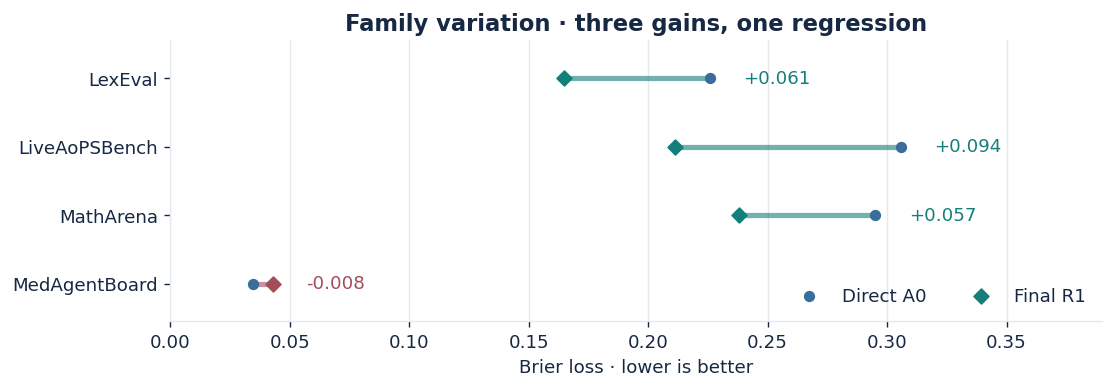

In [12]:
families = sorted({c["family"] for c in cell_data["cells"]})
by_family = {}
for family in families:
    rows = [c for c in cell_data["cells"] if c["family"] == family]
    by_family[family] = [
        np.mean([c["loss_sums"][m]["brier"] / c["n_trials"] for c in rows])
        for m in ("A0", "R1")
    ]
    ref = reference["decomposition"][family]
    assert np.allclose(by_family[family], [ref["A0_brier"], ref["final_brier"]], atol=1e-12)
names = ["LexEval", "LiveAoPSBench", "MathArena", "MedAgentBoard"]
order = [x.lower() for x in names]
fig, ax = plt.subplots(figsize=(8.8, 3), layout="constrained")
for y, family in enumerate(order):
    a, b = by_family[family]
    color = TEAL if a > b else RED
    ax.plot([a, b], [y, y], color=color, linewidth=3, alpha=.6)
    ax.scatter(a, y, color=BLUE, s=30, label="Direct A0" if y == 0 else None, zorder=3)
    ax.scatter(b, y, color=color, marker="D", s=36, label="Final R1" if y == 0 else None, zorder=3)
    ax.text(max(a, b)+.014, y, f"{a-b:+.3f}", va="center", color=color)
ax.set(yticks=range(4), yticklabels=names, xlim=(0,.39), ylim=(3.55,-.55),
       xlabel="Brier loss · lower is better", title="Family variation · three gains, one regression")
ax.grid(axis="x", color=GRID)
ax.legend(loc="lower right", frameon=False, ncol=2)
plt.show()

MedAgentBoard regresses. The overall point estimate is meaningful on the frozen
panel, while the family chart shows why it is risky to generalize the mean.

<a id="hosted"></a>

## 07 · Hosted BLE 1.5-A score dashboard

**Official formative Brier ALC · 0.1590607804.** Submission #1032237 finished
with nine scored subject–benchmark groups and 489 distinct subject–item pairs
across all six budgets. That is **2,934 nominal pair-budget prediction slots**.
The organizer's feedback does not establish the actual number of executed
worker calls, API requests or completed native submits. Group labels below
are arbitrary ordinals, with no private benchmark mapping.

In [13]:
host = read_json("results/hosted_ble15a_aggregates/score.json")
groups = pd.read_csv(ROOT / "results/hosted_ble15a_aggregates/groups.csv", dtype=str)
assert len(groups) == host["groups"] == 9
assert groups["pairs"].astype(int).sum() == host["distinct_pairs"] == 489
assert host["distinct_pairs"] * len(BUDGETS) == host["nominal_pair_budget_slots"] == 2934
assert tuple(map(lambda x: Decimal(str(x)), host["official_weights"])) == WEIGHTS
displayed = dict(zip(BUDGETS, host["displayed_mean_brier"]))
group_brier = {b: sum(map(Decimal, groups[f"b{b}"])) / len(groups) for b in BUDGETS}
official = Decimal(host["official_formative_alc"])
reconstructions = {
    "Official headline": official,
    "Six displayed means": alc(displayed),
    "Means of rounded group budget cells": alc(group_brier),
    "Mean of rounded group ALCs": sum(map(Decimal, groups["published_group_alc"])) / len(groups),
}
assert all(abs(value - official) < Decimal("0.000001") for value in reconstructions.values())
display(pd.DataFrame([{"Source": name, "Brier ALC": f"{value:.10f}",
                       "Difference": f"{value-official:+.10f}"} for name, value in reconstructions.items()]))

,Source,Brier ALC,Difference
0,Official headline,0.1590607804,+0.0000000000
1,Six displayed means,0.1590607000,-0.0000000804
2,Means of rounded group budget cells,0.1590608444,+0.0000000640
3,Mean of rounded group ALCs,0.1590606667,-0.0000001137


The official headline is the primary result. The rounded means reproduce it
within one millionth. None of the rounding paths needs a private outcome.

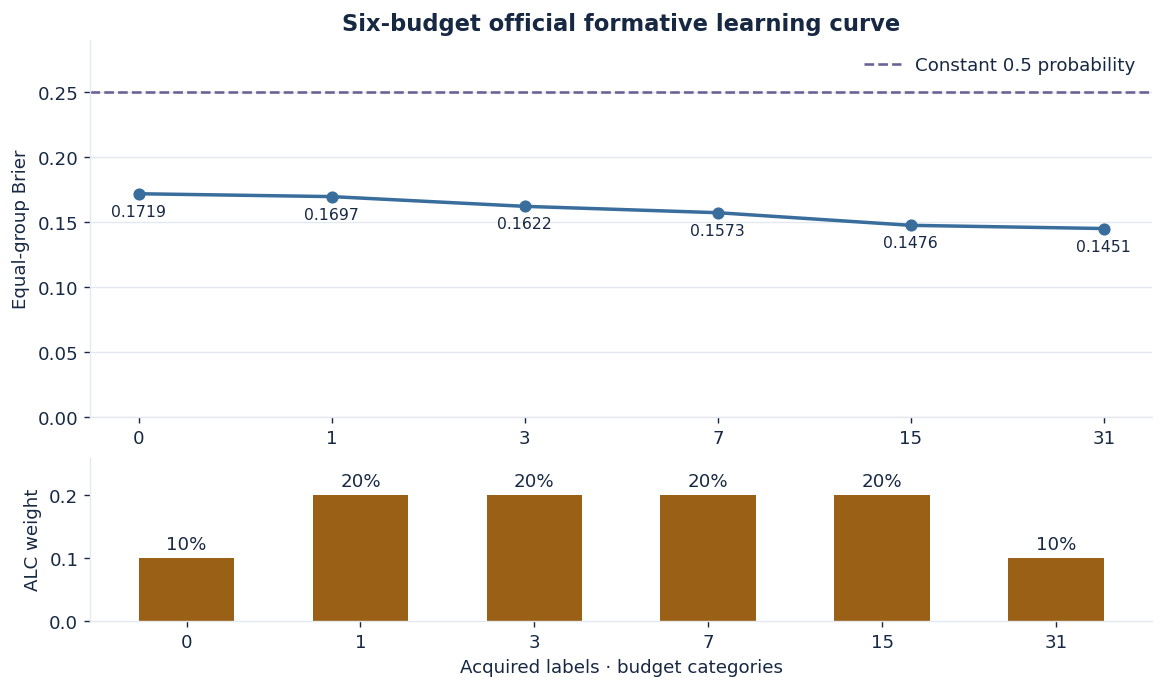

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(9.2, 5.4), layout="constrained",
                         gridspec_kw={"height_ratios":[2.3,1]})
positions = np.arange(len(BUDGETS))
scores = [displayed[b] for b in BUDGETS]
axes[0].plot(positions, scores, color=BLUE, marker="o", linewidth=2)
axes[0].axhline(.25, color=LAVENDER, linestyle="--", label="Constant 0.5 probability")
for x, val in zip(positions, scores):
    axes[0].annotate(f"{val:.4f}", (x, val), xytext=(0,-13), textcoords="offset points", ha="center", fontsize=9)
axes[0].set(xticks=positions, xticklabels=BUDGETS, ylim=(0,.29),
            ylabel="Equal-group Brier", title="Six-budget official formative learning curve")
axes[0].legend(frameon=False)
axes[0].grid(axis="y", color=GRID)
bars = axes[1].bar(positions, list(map(float, WEIGHTS)), color=AMBER, width=.55)
axes[1].bar_label(bars, labels=[f"{w:.0%}" for w in WEIGHTS], padding=3)
axes[1].set(xticks=positions, xticklabels=BUDGETS, ylim=(0,.26),
            xlabel="Acquired labels · budget categories", ylabel="ALC weight")
plt.show()

More acquired labels coincided with lower mean Brier in this evaluation. The
curve is descriptive. It does not isolate the effect of a different acquisition
policy or retrieval. The dashed line is the constant 0.5 reference.

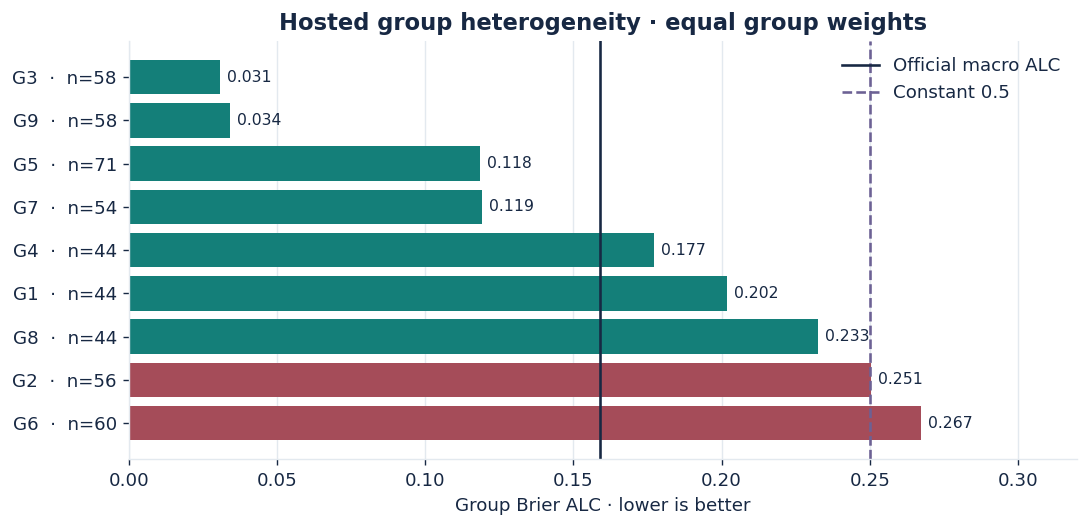

In [15]:
ordered = groups.assign(alc=groups.published_group_alc.astype(float)).sort_values("alc")
labels = [f"{g}  ·  n={n}" for g, n in zip(ordered.group, ordered.pairs)]
fig, ax = plt.subplots(figsize=(8.6, 4.1), layout="constrained")
bars = ax.barh(labels, ordered.alc, color=[TEAL if x < .25 else RED for x in ordered.alc])
ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=9)
ax.axvline(float(official), color=NAVY, linewidth=1.5, label="Official macro ALC")
ax.axvline(.25, color=LAVENDER, linestyle="--", label="Constant 0.5")
ax.invert_yaxis()
ax.set(xlim=(0,.32), xlabel="Group Brier ALC · lower is better",
       title="Hosted group heterogeneity · equal group weights")
ax.grid(axis="x", color=GRID)
ax.legend(frameon=False, loc="upper right")
plt.show()

The aggregate conceals a wide spread. These groups must stay anonymous. The
public R1 result **0.153728** and hosted ALC **0.1590607804** use different
questions, evidence protocols and aggregation, so their numerical proximity
does not measure transfer or degradation.

<a id="decisions"></a>

## 08 · What worked, what failed, and why it matters

A result can be interesting yet too weak for promotion. Each row puts the test,
number, inference boundary and engineering decision together. The adapter arm
called A2 in the native-tool study is distinct from hosted Fast submission A.2.

In [16]:
ledger = pd.read_csv(ROOT / "results/decision_ledger.csv")
assert len(ledger) == 9 and ledger["Experiment"].is_unique
display(ledger.set_index("Experiment"))

,Hypothesis,Test,Measured result,Limitation,Decision
Experiment,,,,,
Research R1,Recurrent beliefs improve on direct predictions,Frozen paired public 32-question outcome-seale...,0.050155 lower Brier; clustered interval [0.00...,Four previously encountered families; retrieva...,Retain controlled evidence
Ledger and shrinkage,Label-informed adjustments generalize,Ledger paired eight-family test and separate h...,Ledger B7 gain 0.014907 with interval spanning...,Proxy is not scored Completion A and broad pan...,Keep frozen A
Inductive factor model,Low-rank item embeddings transfer,Two strict seven-label cross-family directions,Factor 0.340420 vs scalar 0.272994; reverse 0....,Different panel from BLE; no paired BLE compar...,Reject strict transfer variant
Early stopping,Stable beliefs cut paid rounds,Offline prefix replay on 49 valid Standard rea...,96 vs 99 attempts; 3.03% saved; separate four-...,Counterfactual replay and limited support; no ...,Do not promote
Prior hosted deployments,The full pipeline survives platform execution,Original R1 production #1031040 and Fast insur...,Both failed; no score,No verified specific root cause for these fail...,Keep separate from scored A
Scored A,Completion policy can produce official score,Codabench #1032237,Finished; formative ALC 0.1590607804 on nine g...,Counted runtime and readout coverage unavailable,Selected hosted evidence
Fast A.2,Same source with Fast tier could reduce wait,Codabench #1033843,Failed; PAIEC-UNKNOWN-001,No classified cause; timeout unverified,No hosted speed claim
Native parallel tool calls,Batching saves end-to-end time,Five fully matched public cases in a separate ...,2.20 vs 3.00 requests but 24.86 vs 19.90 seconds,No native finalization in batched arm; B31 inc...,Do not expand
Runtime and concurrency,Worker scheduling explains hosted bottleneck,Local official-pool replay plus scope-local ho...,4/8/16 local slots filled; hosted overlap rema...,Synthetic replay and scope ambiguity; hosted a...,No optimization selected


The rejected attempts illustrate three recurring pitfalls: a label correction
can double-count evidence, a shortcut can save requests without saving time, and
a change that works within a family can fail in strict transfer. The final
selection was not retuned against hidden target labels.

<a id="reliability"></a>

## 09 · Reliability, runtime and observability

| Outcome | Meaning |
|---|---|
| Finalized | The scored controller accepted an explicit native submit. |
| Earlier valid belief | A previous model-derived probability was retained after an interruption. |
| Invalid output | Schema, metadata or probability checks rejected a response. A valid repair or previous belief may still exist. |
| Batch-fatal error | The run could not return normally under the runner contract. |
| Confirmed total-runtime timeout | A specific timeout diagnostic or trusted measured deadline is available. A prolonged UI state is insufficient. |

**A.2 local stress coverage.** These 3,000 mocked forecasts and 200 injected
faults exercise known paths. They cannot estimate a real-world rate. Separately,
hosted A.2 #1033843 reported PAIEC-UNKNOWN-001 and has no established cause.

In [17]:
stress = read_json("results/reliability.json")
assert stress["native_finalizations"] + stress["earlier_belief_readouts"] == stress["forecasts"]
assert (stress["requests"], stress["injected_faults"], stress["emergency_readouts"]) == (9020, 200, 0)
display(pd.DataFrame([{
    "Campaign": "A.2 local mocked engineering",
    "Forecasts": stress["forecasts"], "Mock requests": stress["requests"],
    "Injected faults": stress["injected_faults"], "Native submits": stress["native_finalizations"],
    "Earlier beliefs": stress["earlier_belief_readouts"], "Emergency": stress["emergency_readouts"]
}]).set_index("Campaign"))

,Forecasts,Mock requests,Injected faults,Native submits,Earlier beliefs,Emergency
Campaign,,,,,,
A.2 local mocked engineering,3000,9020,200,2820,180,0


The time budget combines cold SQLite hydration, first-use MiniLM loading,
sequential API and local tool turns, plus worker scheduling and provider limits.
Local replay filled 4, 8 and 16 configured slots. Hosted overlap and the
organizer-counted execution duration remain unresolved. The official eight-hour
rule still applies. One unknown-cause failure is not evidence of a timeout.

A small failure chance can matter across thousands of tasks. **For illustration
only**, if failures are independent with constant probability q, at least one
fails with probability 1 − (1 − q)ⁿ. Correlation, recoverable errors and platform
behavior can invalidate this calculation for a real batch.

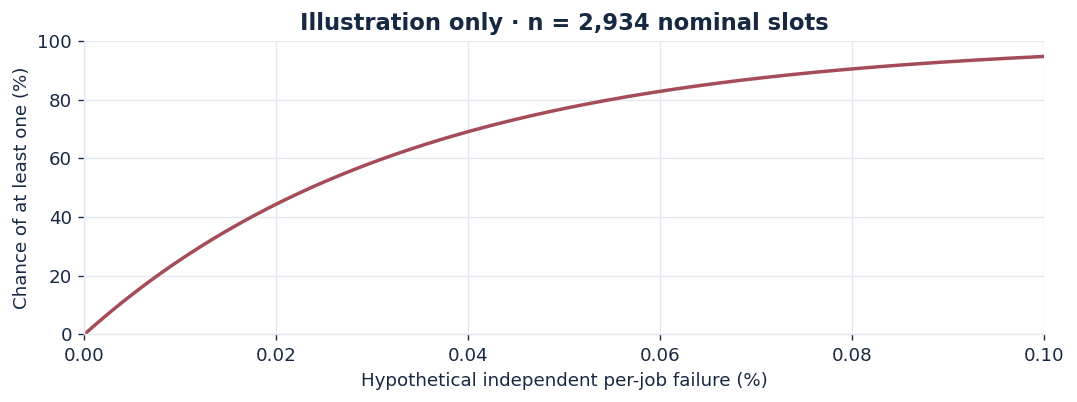

In [18]:
q = np.linspace(0, .001, 200)
n = host["nominal_pair_budget_slots"]
fig, ax = plt.subplots(figsize=(8.5, 3.1), layout="constrained")
ax.plot(q*100, -np.expm1(n*np.log1p(-q))*100, color=RED, linewidth=2)
ax.set(xlim=(0,.1), ylim=(0,100), xlabel="Hypothetical independent per-job failure (%)",
       ylabel="Chance of at least one (%)",
       title=f"Illustration only · n = {n:,} nominal slots")
ax.grid(color=GRID)
plt.show()

The curve is a sensitivity example. It contains no fitted failure probability
and makes no reliability claim for A or A.2.

<a id="reproduce"></a>

## 10 · Reproduce the permitted portions

### Offline demonstration mode · default

After installing the pinned [notebook dependencies](../requirements-notebook.txt),
run all cells from the repository root or notebooks directory. There are no API
calls, downloads or hosted labels in this path. The toy database, mock transport,
source assertions and released aggregate checks are enough to learn and test
the core behavior. [Offline runner](../scripts/verify_notebook.py)

### Real BLE 1.5-A mode · separate opt-in

Outside this notebook, follow the [hash-bound restore instructions](../hosted-ble15a/README_OPENREVIEW.md)
to build a private offline-default runtime and run the official checker and smoke.
Supply only authorized inputs. Real execution needs six exact derived data
files, the pinned MiniLM weight, compatible dependencies, an approved account,
an operator's own private credential, and explicit spending authorization.
Never place credentials in this notebook or Git. No cell enables inference.
The [reproduction guide](../docs/reproduction.md) documents the private
configuration gate and cost accounting.

The frozen wrapper reserves up to $1 per forecast and $50 per shared execution
scope. These are conservative safeguards, not a quote, bill, or provider cap.
A call's expected cost depends on input/output and cache pricing. Read the
current official pricing before spending. Separate execution scopes or replays
can multiply the exposure. Exact independent reconstruction remains blocked
without an authorized derived-asset handoff.
[OpenAI pricing](https://openai.com/api/pricing/)

In [19]:
manifest = read_json("hosted-ble15a/ARTIFACT_MANIFEST.json")
validation = read_json("hosted-ble15a/RECONSTRUCTION_VALIDATION.json")
assert manifest["original_scored_archive"]["submission_id"] == 1032237
assert validation["effective_budgets"] == list(BUDGETS)
assert validation["paid_requests"] == 0
external = [x for x in manifest["members"] if x["delivery"] != "bundled"]
assert len(external) == 7 and sum(x["delivery"] == "authorized-exact-data" for x in external) == 6
display(pd.DataFrame([{
    "Exact external member": x["path"], "MiB unpacked": round(x["bytes"]/2**20, 2),
    "Source class": x["delivery"]
} for x in external]).set_index("Exact external member"))

,MiB unpacked,Source class
Exact external member,,
data/evidence.xz.bin,364.42,authorized-exact-data
data/firewall_static_cache.json,0.01,authorized-exact-data
data/protected_inputs.json,0.52,authorized-exact-data
data/semantic_items.json,4.69,authorized-exact-data
data/semantic_vectors.npy,20.21,authorized-exact-data
data/traces_chunked.sqlite,296.89,authorized-exact-data
models/minilm/model.safetensors,86.66,public-minilm


The earlier authorized full restore verified 70 of 72 member contents and
passed the checker, smoke and six-budget real-local-retrieval tests with mocked
responses. The two changes are the safe config and regenerated hash manifest.
The supplement-only clean-room attempt stopped at the missing corpus.
This is verified reconstruction conditional on asset access, with no new
measurement of the hosted score.

<a id="conclusions"></a>

## 11 · Limitations and conclusions

**What we learned.** On a bounded public panel, the organizer-derived BLE
protocol improved on direct Luna and much of the difference was already present
in the initial belief. Later revisions improved the aggregate on that panel
with a regression in one family. A separately deployed, audited Completion
runtime produced official formative ALC 0.1590607804 on the hosted evaluation.

**What remains open.** The experiment does not isolate retrieval causality,
establish unseen-family generalization, reveal the hosted rate of prior-belief
readouts, or measure counted execution time. Public access to six exact derived
assets remains unresolved. We release enough to inspect the frozen source,
reconcile published numbers, and reproduce the offline demonstrations.

[Technical report](../paper/PAIEC_BLE_NeurIPS2026_Reconstructed.pdf) ·
[Scored entry point](../hosted-ble15a/runtime/model.py) ·
[Controller](../hosted-ble15a/runtime/r1api/predictor.py) ·
[Source equivalence](../docs/release_manifest.md) ·
[Claims ledger](../docs/scientific_claims.md) · [Back to overview](#overview)